<a href="https://colab.research.google.com/github/MrSottaceti/Time-series/blob/main/Filtri_convoluzionali_e_ricorsivi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
install.packages("astsa")
library(astsa)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



#Funzione FILTER in R:

    help(filter)
Applies linear filtering to a univariate time series or to each series separately of a multivariate time series.

    filter(x, filter, method = c("convolution", "recursive"),
            sides = 2, circular = FALSE, init)

    method: Either ‘"convolution"’ or ‘"recursive"’ (and can be
          abbreviated). If ‘"convolution"’ a moving average is used: if
          ‘"recursive"’ an autoregression is used.

Un filtro convolutivo combina valori dell'input, mentre un filtro ricorsivo utilizza anche valori precedenti del proprio output. Sia $x_t$ la serie originale e $y_t$ la serie filtrata:

## Filtro convolutivo

Un filtro convolutivo è una trasformazione del tipo
$$y_t=\sum_{j=0}^{q}h_jx_{t-j}$$
Matematicamente stiamo affettuando un'operazione di tipo $y_t=(h* x)_t$ con il vettore dei coefficienti, $h$, detto anche **kernel**, che scorre lungo la serie temporale effettuando un prodotto scalare.

## Filtro ricorsivo

$$y_t=x_t+\sum_{j=1}^{p}a_jy_{t-j}$$

Nella sommatoria compaiono gli output passati $y_{t-j}$, non gli input passati $x_{t-j}$.
Un filtro ricorsivo può essere visto come una convoluzione con un **kernel infinito**.

# Gaussian white noise e media mobile

Simuliamo un rumore bianco gaussiano $w_t\sim \mathcal N(0,1)$ e calcoliamo una media mobile di tre periodi $v_t=\frac13(w_{t-1}+w_t+w_{t+1})$

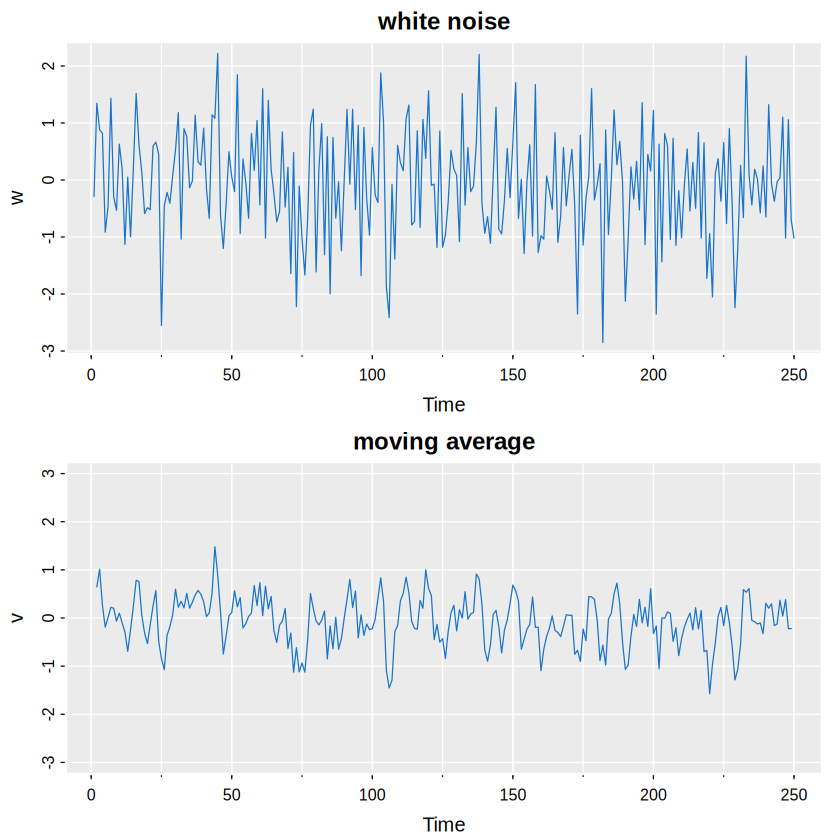

In [4]:
w = rnorm(250) # 250 N(0,1) variates
v = filter(w, sides=2, filter=rep(1/3,3)) # moving average
par(mfrow=2:1)
tsplot(w, main="white noise", col=4, gg=TRUE)
tsplot(v, ylim=c(-3,3), main="moving average", col=4, gg=TRUE)

Dal punto di vista matematico, stiamo applicando un **filtro lineare centrato** al rumore bianco:
$$
v_t=\frac{w_{t-1}+w_t+w_{t+1}}{3}
$$

Partendo da un processo senza autocorrelazione otteniamo un processo autocorrelato con varianza minore. È anche uno dei punti di contatto fondamentali tra analisi delle serie storiche ed elaborazione dei segnali.

Un filtro è un operatore matematico che trasforma un segnale di input in un segnale di output. Lo scopo è modificare alcune proprietà del segnale:
- attenuare il rumore;
- estrarre il trend;
- eliminare la stagionalità;
- isolare determinate frequenze;
- stimare componenti latenti;
- individuare anomalie;
- rendere stazionario un processo.



#Filtro Autoregressivo

Generiamo un processo autoregressivo AR(2) mediante un **filtro lineare ricorsivo** applicato al rumore bianco:

$$ X_t=1.5X_{t-1}-0.75X_{t-2}+w_t$$
$$w_t\overset{iid}\sim \mathcal N(0,1)$$

Il processo è inizializzato con $X_0=X_{-1}=0$


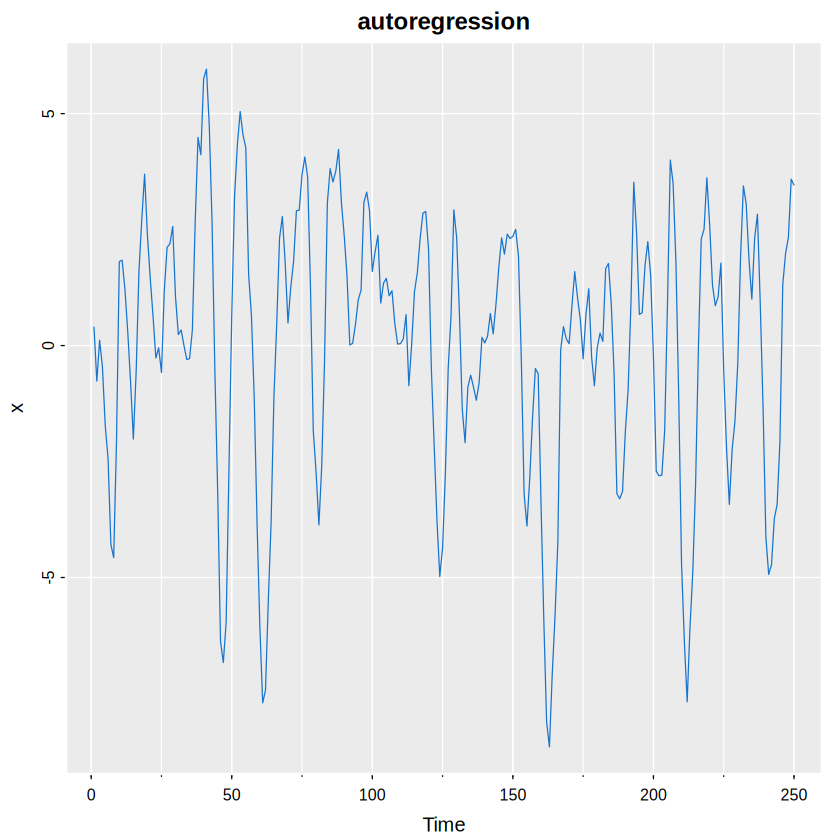

In [5]:
w = rnorm(300) # 50 extra to avoid startup problems
x = filter(w, filter=c(1.5,-.75), method="recursive")[-(1:50)] #eliminiamo le prime 50 oss (burn in)
tsplot(x, main="autoregression", col=4, gg=TRUE)

Il processo è stazionario infatti le radici del polinomio sono fuori dal cerchio unitario

In [7]:
roots <- polyroot(c(1, -1.5, 0.75))

roots
Mod(roots)

[1] 1+0.5773503i 1-0.5773503i

[1] 1.154701 1.154701

### Alcune osservazioni

1. Il filtro è "ricorsivo": nel caso della media mobile, l'output dipendeva dai valori dell'input. Nel caso autoregressivo, l'output dipende anche dai propri valori precedenti.

2. Le prime 50 osservazioni sono state tolte.
[-(1:50)]. Questa operazione prende il nome di burn-in. Il processo viene inizializzato artificialmente con $X_0=X_{-1}=0$.
Queste condizioni iniziali potrebbero non essere rappresentative della distribuzione stazionaria del processo.Generiamo quindi 300 osservazioni e scartiamo le prime 50, lasciando che l'effetto dell'inizializzazione si attenui.

3. Il processo è stazionario. Le radici sono: $z_{1,2}=1\pm0.57735i$, maggiori di 1 in modulo. Le radici complesse del polinomio autoregressivo producono una **dinamica oscillatoria smorzata**. Il processo può quindi manifestare comportamenti quasi ciclici, nonostante sia alimentato esclusivamente da rumore bianco.

NB: Un processo autoregressivo è un sistema dinamico che trasforma shock casuali in una struttura temporale persistente, eventualmente oscillatoria. Non occorre introdurre esplicitamente un ciclo per generare un comportamento ciclico.

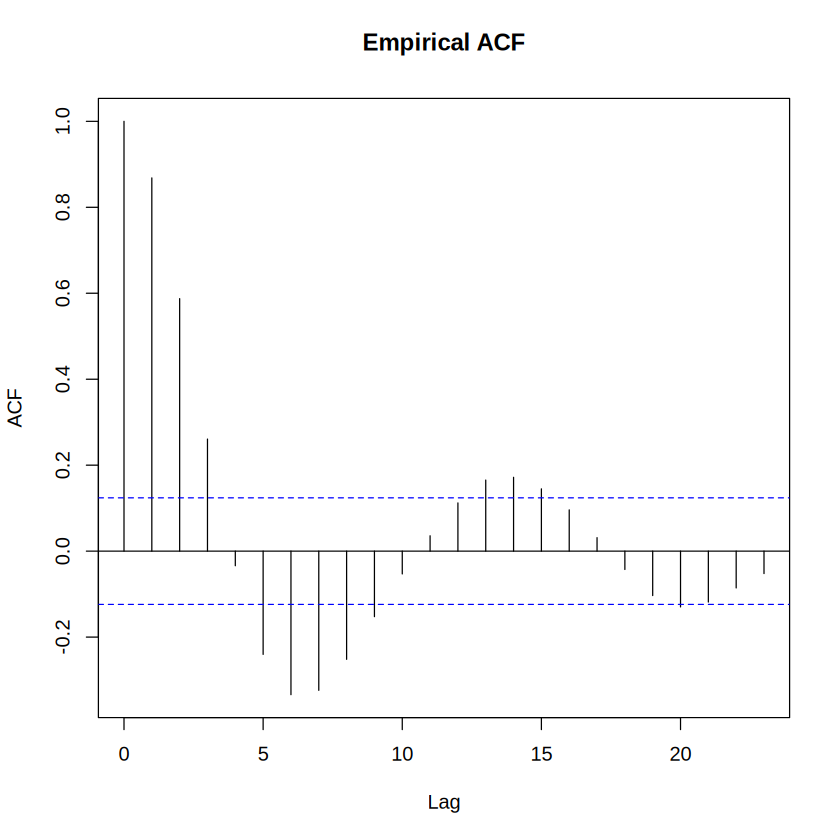

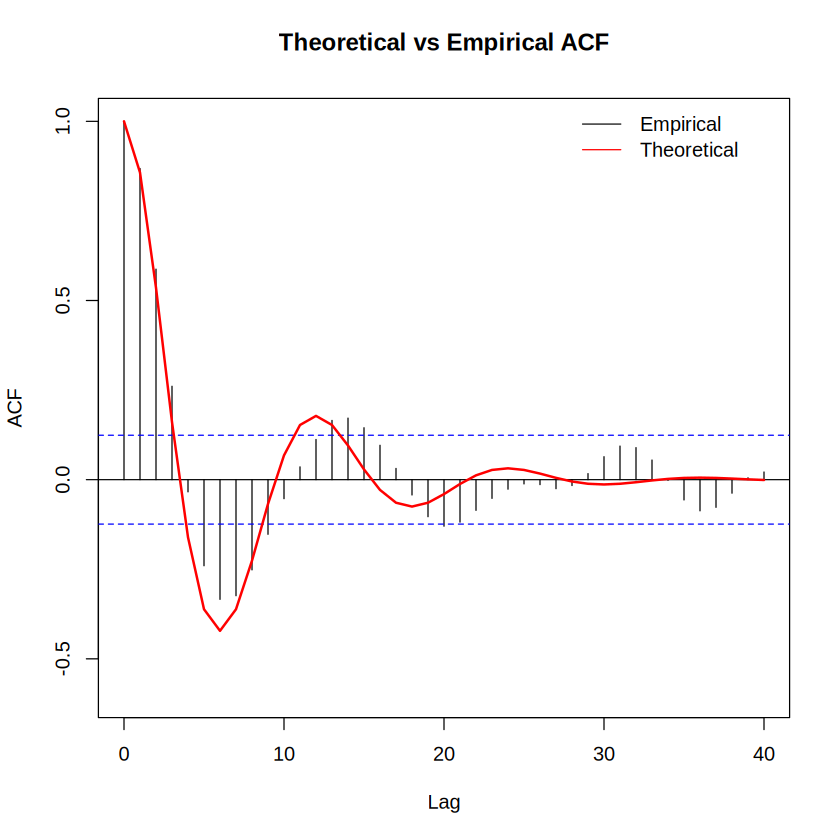

In [17]:
acf(x, main = "Empirical ACF")

rho <- ARMAacf(ar = c(1.5, -0.75), lag.max = 40)
acf(x, lag.max = 40,
    main = "Theoretical vs Empirical ACF",
    ylim = c(-0.6, 1))
lines(0:40, rho,
      col = "red",
      lwd = 2)
legend("topright", legend = c("Empirical", "Theoretical"), col = c("black", "red"), lty = 1, bty = "n")

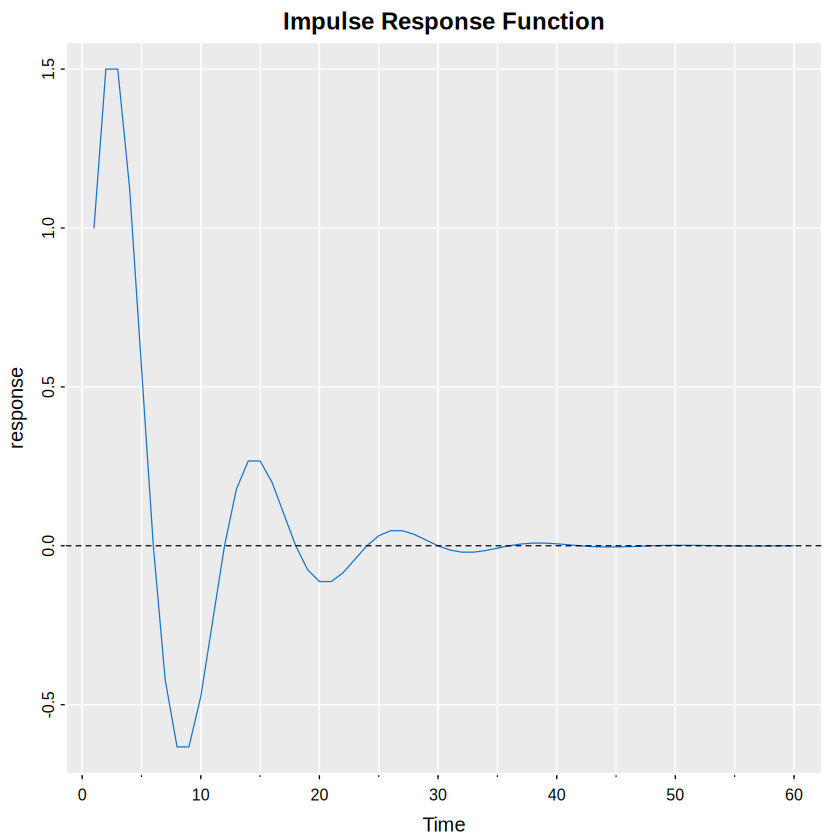

In [18]:
impulse <- c(1, rep(0, 59))

response <- stats::filter(
    impulse,
    filter = c(1.5, -0.75),
    method = "recursive"
)

tsplot(response,
       main = "Impulse Response Function",
       col = 4,
       gg = TRUE)

abline(h = 0, lty = 2)

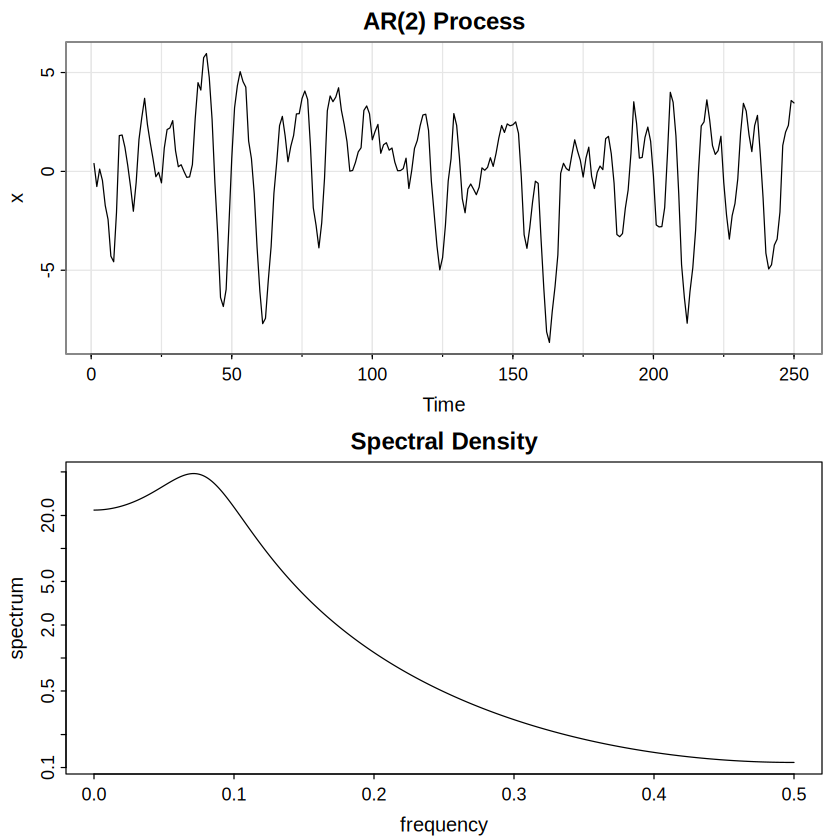

In [9]:
par(mfrow = c(2, 1))

tsplot(x, main = "AR(2) Process")

spec.ar(x, order = 2, main = "Spectral Density")